# Task 5: Hiring Trend Analysis

Run `python src/trends.py` first. All tables in `data/processed/` use one shared structure, `company_name` + `week_start` / `month_start` + metrics, which Task 7 (forecasting) reads directly. No description text, so everything is committable.

**Two views with opposite weaknesses.** The posting-date series is long but biased: feeds only list roles that are still open, so older weeks look emptier than they were. The snapshot flows are unbiased (we watch roles open and close) but short, since 4 Nov 2026. The headline unit is the *unique role*: one role posted in ten cities counts once.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
P = "../data/processed/"
weekly = pd.read_csv(P + "weekly_postings.csv", parse_dates=["week_start"])
monthly = pd.read_csv(P + "monthly_postings.csv")
flows = pd.read_csv(P + "snapshot_flows.csv", parse_dates=["snapshot_date"])
summ = pd.read_csv(P + "velocity_summary.csv")
role = pd.read_csv(P + "role_velocity.csv")
wd = pd.read_csv(P + "posting_weekday.csv")
fix = pd.read_csv("../docs/posting_date_fix.csv")

ORDER = ["OpenAI", "Anthropic", "Databricks", "NVIDIA"]
COLOR = {"OpenAI": "#1c5cab", "Anthropic": "#d9772b", "Databricks": "#b5342c", "NVIDIA": "#3f8f2f"}
GREY = "#8b949e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print(f"Weeks {weekly.week_start.min():%d %b %Y} to {weekly.week_start.max():%d %b %Y} ({weekly.week_start.nunique()} complete weeks)")

Weeks 25 May 2026 to 16 Nov 2026 (26 complete weeks)


## 1. Weekly new roles per company

Raw postings, unique roles, and the survivorship-adjusted series. The adjustment divides by a survival curve S(age) built from how fast jobs of each age closed between snapshots (factor capped at 3). Triangles mark weeks above or below the recent median by more than 3 MAD, tested on the adjusted series.

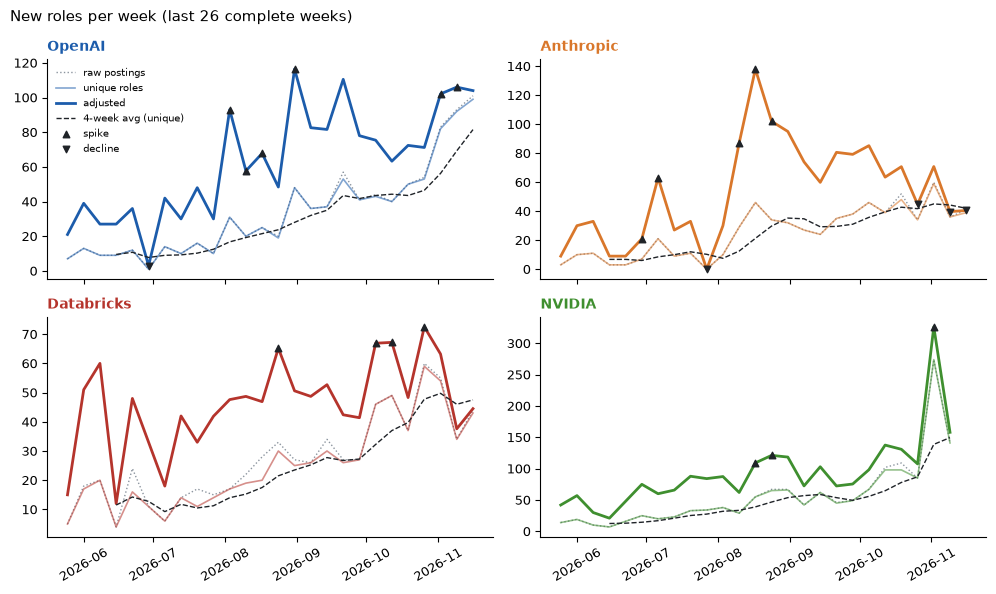

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, c in zip(axes.flat, ORDER):
    d = weekly[weekly.company_name == c]
    ax.plot(d.week_start, d.new_postings_raw, color=GREY, lw=1, ls=":", label="raw postings")
    ax.plot(d.week_start, d.new_roles_unique, color=COLOR[c], lw=1.2, alpha=.55, label="unique roles")
    ax.plot(d.week_start, d.new_roles_adjusted, color=COLOR[c], lw=2, label="adjusted")
    ax.plot(d.week_start, d.rolling_4w, color="#1f2328", lw=1, ls="--", label="4-week avg (unique)")
    for flag, mk in (("spike", "^"), ("decline", "v")):
        f = d[d.spike_flag == flag]
        ax.scatter(f.week_start, f.new_roles_adjusted, marker=mk, color="#1f2328", s=22, zorder=3,
                   label=flag if c == "OpenAI" else None)
    ax.set_title(c, loc="left", fontsize=10, color=COLOR[c], fontweight="bold")
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].legend(fontsize=7, frameon=False, loc="upper left")
fig.suptitle("New roles per week (last 26 complete weeks)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

**Reading it:** raw and unique lines rise steadily towards today for every company. That is mostly survivorship, not acceleration: recent postings are still open, older ones have gone. The adjusted line is the fairer view, and it is much flatter from September. Before about August the correction hits its 3x cap, so those weeks are a floor, not an estimate, and flags there are weak evidence.

## 2. NVIDIA before and after the repost fix

Workday resets `startDate` when roles are reposted in bulk. Raw dates put 1,351 roles on 30 Oct, a fake spike. The requisition-number estimate was not accurate enough (see table), so the bulk-repost roles are flagged `bulk_repost` and left out of new-posting counts but kept in open-stock counts. A day only counts as a repost if it is busy *and* its requisition numbers are older than normal, so genuinely busy days stay in.

company_name              bulk_days  bulk_postings  mae_days                                                        route
   Anthropic                    NaN              0       NaN                                                         none
  Databricks                    NaN              0       NaN                                                         none
      NVIDIA 2026-10-30; 2026-10-31           1415      37.2 bulk_repost (kept dates, excluded from new-posting velocity)
      OpenAI                    NaN              0       NaN                                                         none


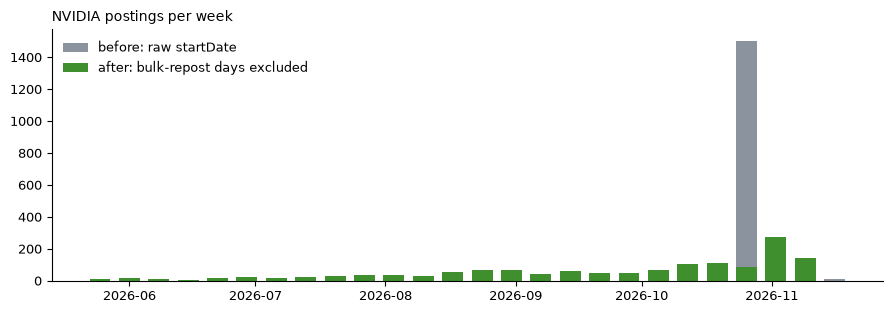

In [3]:
print(fix[["company_name", "bulk_days", "bulk_postings", "mae_days", "route"]].to_string(index=False))
m = pd.read_csv("../data/interim/jobs_clean.csv", usecols=["company_name", "posting_date", "posting_date_raw"])
n = m[m.company_name == "NVIDIA"]
wk = lambda s: pd.to_datetime(s, utc=True).dt.tz_localize(None).dt.to_period("W-SUN").dt.start_time
before = wk(n.posting_date_raw).value_counts().sort_index()
after = weekly[weekly.company_name == "NVIDIA"].set_index("week_start").new_postings_raw
before = before[before.index >= after.index.min()]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(before.index, before.values, width=5, color=GREY, label="before: raw startDate")
ax.bar(after.index, after.values, width=5, color=COLOR["NVIDIA"], label="after: bulk-repost days excluded")
ax.set_title("NVIDIA postings per week", loc="left", fontsize=10); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Reading it:** the 2026-W44 spike (week of 26 Oct) disappears. The rule flags 30 and 31 Oct (1,415 roles). 2 and 3 Nov were also busy, but their requisition numbers are new, so they stay in and make the week of 2 Nov NVIDIA's largest (274 unique roles, flagged as a spike). For NVIDIA, cross-check against the snapshot flows below, which are provisional (one 12-day interval).

## 3. Snapshot flows: opened vs closed, and open stock

Real snapshot dates; the baseline snapshot (4 Nov) is excluded from "opened". Intervals where a company's snapshot failed are skipped, so NVIDIA has one interval so far.

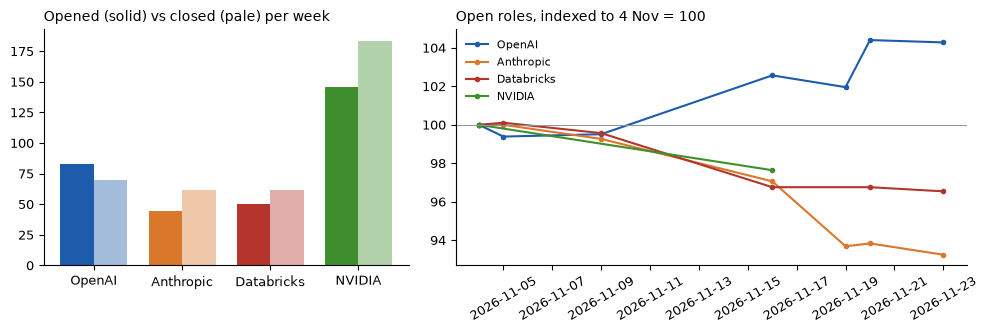

,company_name,opened_per_week,closed_per_week,open_stock_baseline,open_stock_latest,open_stock_change_pct
0,Anthropic,44.6,61.5,681,635,-6.8
1,Databricks,50.1,61.9,925,893,-3.5
2,NVIDIA,145.8,183.8,2755,2690,-2.4
3,OpenAI,82.5,69.6,817,852,4.3


In [4]:
iv = flows[~flows.is_baseline].copy()
for c in ("opened", "closed", "days"): iv[c] = iv[c].astype(float)
tot = iv.groupby("company_name").agg(opened=("opened", "sum"), closed=("closed", "sum"), days=("days", "sum"))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1, 1.4]})
x = np.arange(4); w = .38
axes[0].bar(x - w/2, [tot.opened[c] / tot.days[c] * 7 for c in ORDER], w, color=[COLOR[c] for c in ORDER], label="opened")
axes[0].bar(x + w/2, [tot.closed[c] / tot.days[c] * 7 for c in ORDER], w, color=[COLOR[c] for c in ORDER], alpha=.4, label="closed")
axes[0].set_xticks(x, ORDER); axes[0].set_title("Opened (solid) vs closed (pale) per week", loc="left", fontsize=10)
for c in ORDER:
    d = flows[flows.company_name == c]
    axes[1].plot(d.snapshot_date, d.open_postings / d.open_postings.iloc[0] * 100, marker="o", ms=3, color=COLOR[c], label=c)
axes[1].axhline(100, color=GREY, lw=.7); axes[1].legend(frameon=False, fontsize=8)
axes[1].set_title("Open roles, indexed to 4 Nov = 100", loc="left", fontsize=10); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
summ[["company_name", "opened_per_week", "closed_per_week", "open_stock_baseline", "open_stock_latest", "open_stock_change_pct"]]

**Reading it:** every company closes roles faster than it opens them over this window, except OpenAI, whose open stock is the only one that grew. Anthropic, Databricks and NVIDIA shrank by 2-6%. Churn is high everywhere: 7-10% of open roles close each week, which is exactly why the posting-date series needs the survivorship correction.

## 4. Role-category velocity

Unique new roles per week, last 8 weeks vs the 8 before, growth on the adjusted series. Terciles across all company x category pairs with at least 10 roles in the window; smaller cells are left blank.

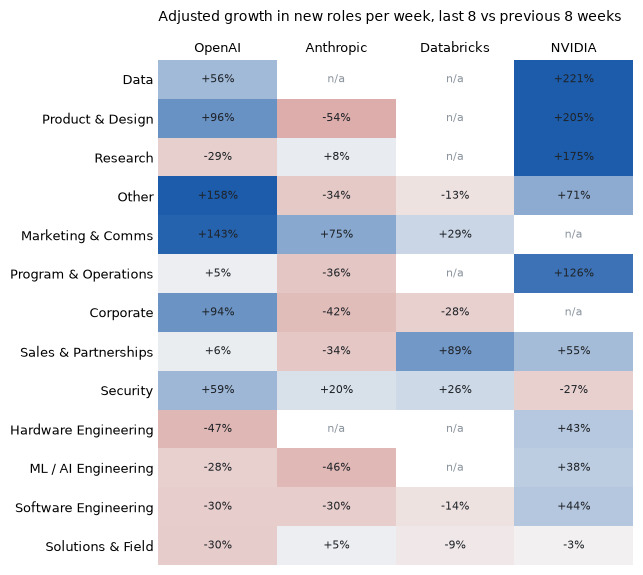

,company_name,role_category,new_roles_per_week_last8,new_roles_per_week_prev8,growth_pct_adjusted
26,NVIDIA,Data,1.38,0.25,221.0
31,NVIDIA,Product & Design,1.88,0.38,205.1
33,NVIDIA,Research,3.88,0.88,175.2
43,OpenAI,Other,8.38,1.75,157.6
42,OpenAI,Marketing & Comms,4.50,1.12,142.7
32,NVIDIA,Program & Operations,2.88,0.88,126.3
44,OpenAI,Product & Design,3.25,0.88,96.3
38,OpenAI,Corporate,3.88,1.25,94.1
21,Databricks,Sales & Partnerships,14.50,4.75,89.1
4,Anthropic,Marketing & Comms,2.50,0.75,74.9


In [5]:
g = role.pivot(index="role_category", columns="company_name", values="growth_pct_adjusted")[ORDER]
elig = role.pivot(index="role_category", columns="company_name", values="hiring_velocity_bucket")[ORDER] != "insufficient data"
g = g.where(elig)
g = g.loc[g.abs().max(axis=1).sort_values(ascending=False).index]
DIV = LinearSegmentedColormap.from_list("div", ["#b5342c", "#f4f4f4", "#1c5cab"])
fig, ax = plt.subplots(figsize=(6.5, 0.34 * len(g) + 1.4))
ax.imshow(g.values, cmap=DIV, vmin=-150, vmax=150, aspect="auto")
for i in range(g.shape[0]):
    for j in range(g.shape[1]):
        v = g.values[i, j]
        ax.text(j, i, "n/a" if np.isnan(v) else f"{v:+.0f}%", ha="center", va="center", fontsize=8,
                color=GREY if np.isnan(v) else "#1f2328")
ax.set_xticks(range(4), ORDER); ax.xaxis.tick_top(); ax.set_yticks(range(len(g)), g.index)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
ax.set_title("Adjusted growth in new roles per week, last 8 vs previous 8 weeks", loc="left", fontsize=10, pad=28)
plt.tight_layout(); plt.show()
role[role.hiring_velocity_bucket == "high"].sort_values("growth_pct_adjusted", ascending=False)[
    ["company_name", "role_category", "new_roles_per_week_last8", "new_roles_per_week_prev8", "growth_pct_adjusted"]]

**Reading it:** OpenAI's growth is in Marketing, Corporate, Product & Design and Security, with Software Engineering and Research roughly flat or down after adjustment. NVIDIA grows broadly across hardware, software, research and data. Databricks growth sits in Sales & Partnerships. Cells with a small base swing wildly, so read the sign and rank, not the exact percentage.

## 5. Day-of-week pattern

Seasonality over months or a year cannot be estimated honestly with under one year of data that also has survivorship bias, so this is the pattern that can be: share of postings by weekday (UTC, postings with a real feed date only).

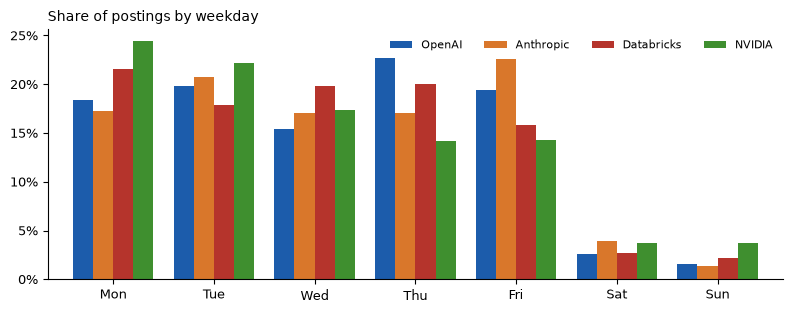

Weekday share (Mon-Fri): {'OpenAI': 96.0, 'Anthropic': 95.0, 'Databricks': 95.0, 'NVIDIA': 92.0}


In [6]:
t = wd.pivot(index="weekday", columns="company_name", values="share").reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])[ORDER]
ax = t.plot.bar(figsize=(8, 3.2), color=[COLOR[c] for c in ORDER], width=.8)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_xlabel(""); plt.xticks(rotation=0)
ax.set_title("Share of postings by weekday", loc="left", fontsize=10); ax.legend(frameon=False, ncol=4, fontsize=8)
plt.tight_layout(); plt.show()
print("Weekday share (Mon-Fri):", (t.loc["Mon":"Fri"].sum() * 100).round(0).to_dict())

**Reading it:** postings are a weekday activity everywhere, 92% or more Monday to Friday. NVIDIA has the most weekend postings (about 8%, against 4-5% elsewhere); the cause is not visible in the data. OpenAI's Wednesday dip is small and unlikely to mean anything with these counts.

## 6. Velocity summary
`hiring_velocity_bucket` uses new unique roles per week (last 4 weeks) as a share of open roles: low below 5%, medium 5-7%, high 7% or more.

In [7]:
summ[["company_name", "new_roles_per_week_last4", "new_roles_per_week_prev4", "growth_pct", "growth_pct_adjusted",
      "new_role_rate_pct_of_open", "hiring_velocity_bucket"]]

,company_name,new_roles_per_week_last4,new_roles_per_week_prev4,growth_pct,growth_pct_adjusted,new_role_rate_pct_of_open,hiring_velocity_bucket
0,Anthropic,42.0,42.8,-1.8,-34.5,6.61,medium
1,Databricks,47.5,39.8,19.5,-2.7,5.32,medium
2,NVIDIA,149.5,64.8,130.9,88.3,5.56,medium
3,OpenAI,81.5,43.5,87.4,32.6,9.57,high
